# Transformación: financiar no equivale a poder ejecutar

## Resumen
El caso sintético inicial refuta una mejora mínima0,5: exacto ygreedy factible empatanNPV11,655966. Relajar precedencias produce18,628099pero un calendario inválido. La contribución es una certificación exacta pequeña de factibilidad temporal, no superioridad universal.

## Modelo ysupuestos
Cada proyecto opcional empieza en un período entero, paga costo al inicio ycobra un beneficio único al terminar. Dependencias deben **terminar** antes del inicio, no basta seleccionarlas. Se respetan presupuesto de caja por período ycapacidad de personas durante toda duración. Budgets expiran: no acumulación, ni financiación con beneficios.

ObjetivoΣ[b_j/(1+r)^(inicio+duración)−c_j/(1+r)^inicio]. Todos datos sintéticos, duraciones deterministas yproyectos no preemptivos. Se enumera también rechazar cada proyecto. No mide riesgo empresarial.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'budgets': [8, 8, 8, 8],
 'people_capacity': 2,
 'discount_per_period': 0.1,
 'jobs': [{'name': 'platform',
   'cost': 4,
   'benefit': 0,
   'duration': 2,
   'people': 1},
  {'name': 'analytics',
   'cost': 3,
   'benefit': 14,
   'duration': 1,
   'people': 1,
   'dependencies': ['platform']},
  {'name': 'automation',
   'cost': 3,
   'benefit': 9,
   'duration': 1,
   'people': 1,
   'dependencies': ['platform']},
  {'name': 'standalone', 'cost': 5, 'benefit': 10, 'duration': 1, 'people': 2},
  {'name': 'controls', 'cost': 2, 'benefit': 1, 'duration': 1, 'people': 1}],
 'units': 'synthetic monetary units; period arbitrary, all cost at start, one benefit at completion; budgets expire and do not accumulate',
 'hypothesis': 'exact feasible NPV >= feasible greedy; original ambition +0.5 is tested and may be refuted'}

## Resultados: baseline factible ehipótesis refutada
Greedy ordena por margen/costo, respeta dependencias temporales yomite actividades negativas que no habilitan otras. No se compara exacto con un greedy que malgaste deliberadamente presupuesto.

{'exact': {'starts': {'platform': 1,
   'analytics': 3,
   'automation': 3,
   'standalone': 0},
  'npv': 11.65596612253261,
  'checked': 2500},
 'baseline': {'starts': {'standalone': 0,
   'platform': 1,
   'analytics': 3,
   'automation': 3},
  'npv': 11.65596612253261,
  'checked': 20},
 'increment': 0.0,
 'dependency_relaxation': {'starts': {'analytics': 0,
   'automation': 0,
   'standalone': 1},
  'npv': 18.628099173553718,
  'checked': 2500},
 'relaxed_schedule_feasible_original': False,
 'seconds': 0.06769287199995233,
 'python_peak_bytes': 2424,
 'python': '3.12.14',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39'}

,policy,job,start,end,cost,benefit,people
0,greedy,platform,1,3,4,0,1
1,greedy,analytics,3,4,3,14,1
2,greedy,automation,3,4,3,9,1
3,greedy,standalone,0,1,5,10,2
4,exact,platform,1,3,4,0,1
5,exact,analytics,3,4,3,14,1
6,exact,automation,3,4,3,9,1
7,exact,standalone,0,1,5,10,2


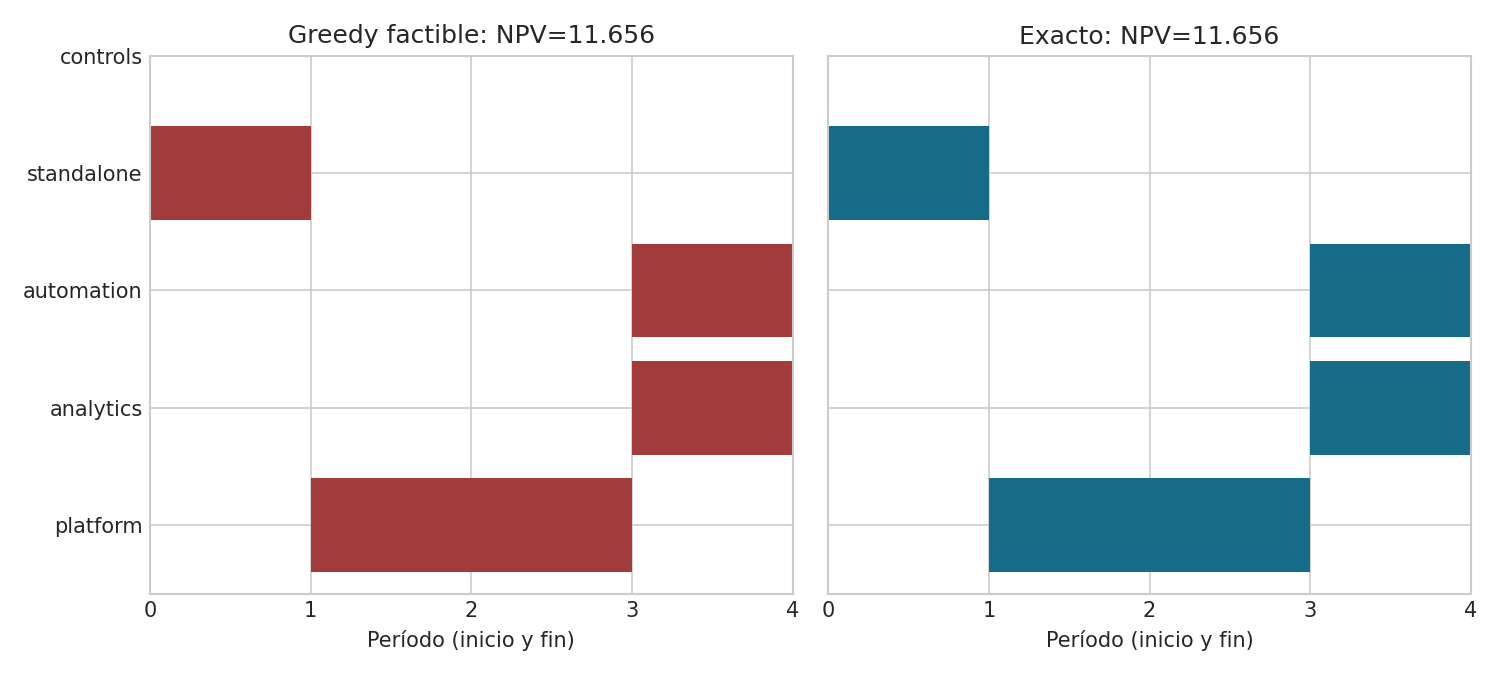

In [2]:
display(summary)
display(pd.read_csv('results/schedules.csv'))
display(Image(filename='results/schedule.png'))

## Sensibilidad yfallos
Aumentar beneficio de analytics puede cambiar elorden óptimo. La ganancia depende del caso; no extrapolar. La pruebaMILP independiente contrasta elvalor óptimo en una instancia distinta. El límite2millones de candidatos impide presentar una búsqueda exponencial como motor escalable.

In [3]:
display(pd.read_csv('results/enabling-value.csv').round(5))
display(pd.read_csv('results/sensitivity.csv').round(5))
assert summary['exact']['npv']>=summary['baseline']['npv']-1e-10
assert summary['increment']==0
assert not summary['relaxed_schedule_feasible_original']

,analytics_benefit,exact_npv,greedy_npv,increment,exact_platform_start
0,14,11.65597,11.65597,0.00000,1
1,20,15.90301,15.75405,0.14897,0
2,30,23.41616,22.58418,0.83198,0


,people,horizon,npv,checked,seconds
0,1,2,0.00000,162,0.00134
1,1,3,4.03907,768,0.00268
2,1,4,7.93225,2500,0.01760
3,1,5,7.93225,6480,0.02470
4,2,2,4.09091,162,0.00069
5,2,3,8.32156,768,0.00285
6,2,4,11.65597,2500,0.00975
7,2,5,11.65597,6480,0.02663
8,3,2,4.09091,162,0.00088
9,3,3,12.04057,768,0.00240


## Decisión ylímites
Continuar con standalone0, platform1 yanalytics/automation3 bajo estos presupuestos. No ejecutar controls, cuyo valor neto es negativo. Ajustar si cambian duraciones, cobros, disponibilidad odependencias; detener si ningún portafolio tieneNPVpositivo. No optimiza contratar personal, incertidumbre, regulación nivalor causal. Ver informe.md yreferencias.bib.